# Univariate uncertainty

**Two forecasts can make exactly the same predictions and still disagree about how sure they are.** One says "about 1.5, but anything from 0 to 3 wouldn't surprise me". The other says "1.5, give or take 0.4". Mean squared error only looks at the predictions, so it gives both the same score. Plan around the second one and you will be surprised far more often than it promised.

In this notebook we fit a simple model to a series, then make an overconfident copy of its forecast: the same predictions with a quarter of the spread. We score both on one series, then on 80 new series, to find out which scores can tell honest uncertainty from overconfidence, and what TimeGym concludes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from timegym import GaussianAR1Forecaster, Scenario, metrics
from timegym.diagnostics import evaluate_forecast
from timegym.mutations import mutate_forecast
from timegym.statistics import paired_t_interval, wilson_interval

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})
COLORS = {"Answer key": "#009E73", "Fitted model": "#0000CC", "Overconfident copy": "#D55E00"}

## An honest forecast

The series reverts to its mean (`ar1`): shocks fade. Each value keeps 80% of the previous value's distance from a long-run level of 2, plus a fresh random shock. The model sees 120 values of history and forecasts the next 12.

The model (`GaussianAR1Forecaster`) returns three things for those 12 steps: a best guess for each step, three quantiles (10%, 50% and 90%), and 256 sample paths. Each sample path is one complete possible future, all 12 steps together.

Because we generated the data, we also hold the **answer key**: the true distribution of the next 12 values, given the history. The model never sees it. Here is what the model learned from the history, next to the truth.

In [2]:
HORIZON, N_SAMPLES = 12, 256
scenario = Scenario("ar1", context_length=120, horizon=HORIZON,
                    parameters={"mean": 2.0, "phi": 0.8, "sigma": 0.8}, seed=17)
case = scenario.generate()
model = GaussianAR1Forecaster(n_samples=N_SAMPLES, seed=2017).fit(case.task.context)  # history only
fitted = model.predict(case.task.future_index)
answer_key = case.reference.forecast(n_samples=N_SAMPLES, seed=1017)

phi, intercept, shock_variance = model.phi_[0], model.intercept_[0], model.cov_[0, 0]
display(pd.DataFrame({"truth": [2.0, 0.8, 0.8],
                      "learned from history": [intercept / (1 - phi), phi, np.sqrt(shock_variance)]},
                     index=["long-run level", "share of a shock left after one step (phi)",
                            "typical shock size (sigma)"]).round(3))

,truth,learned from history
long-run level,2.0,1.649
share of a shock left after one step (phi),0.8,0.758
typical shock size (sigma),0.8,0.854


The estimates are close but not exact. The one that shows up below is the long-run level: the model puts it at 1.65 instead of 2.

## What the forecast looks like

On the left is the answer key, on the right the fitted model. The shaded bands are drawn step by step: the 80% band is an 80% band for each step on its own, not a band the whole path stays inside 80% of the time. The faint lines are a dozen of the sample paths.

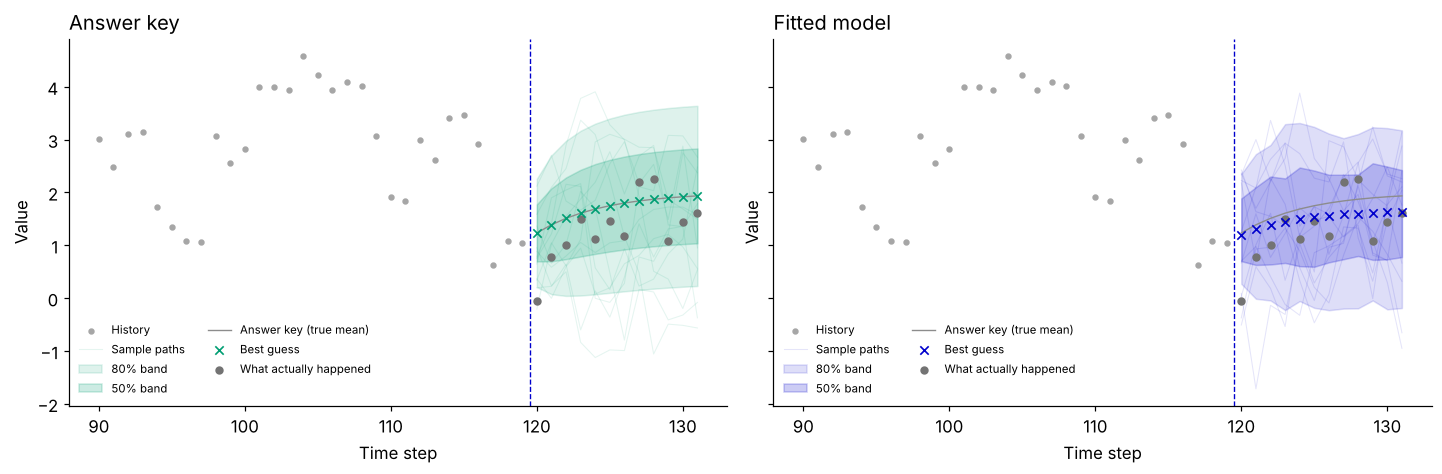

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True, sharey=True, layout="constrained")
future = case.task.future_index.to_numpy()
history = case.task.context.iloc[-30:, 0]
for ax, (name, forecast) in zip(axes, [("Answer key", answer_key), ("Fitted model", fitted)]):
    bands = (case.reference.quantile((0.1, 0.25, 0.75, 0.9))[:, 0, :]
             if name == "Answer key" else
             np.quantile(forecast.samples[:, :, 0], [0.1, 0.25, 0.75, 0.9], axis=0).T)
    ax.scatter(history.index, history, color="0.65", s=10, label="History")
    for i, path in enumerate(forecast.samples[:12, :, 0]):
        ax.plot(future, path, color=COLORS[name], alpha=0.10, linewidth=0.7,
                label="Sample paths" if i == 0 else None)
    ax.fill_between(future, bands[:, 0], bands[:, 3], color=COLORS[name], alpha=0.13, label="80% band")
    ax.fill_between(future, bands[:, 1], bands[:, 2], color=COLORS[name], alpha=0.20, label="50% band")
    ax.plot(future, case.reference.mean[:, 0], color="0.55", linewidth=0.9, label="Answer key (true mean)")
    ax.scatter(future, forecast.point[:, 0], marker="x", color=COLORS[name],
               s=30, linewidths=1.1, label="Best guess", zorder=4)
    ax.scatter(future, case.observed.iloc[:, 0], color="0.45", s=20, label="What actually happened", zorder=3)
    ax.axvline(future[0] - 0.5, color="#0000CC", linestyle="--", linewidth=0.9)
    ax.set(title=name, xlabel="Time step", ylabel="Value")
    ax.legend(fontsize=7.5, loc="lower left", ncol=2)
plt.show()

Both forecasts widen over the first few steps as shocks pile up, then settle. The fitted model's best guesses level off lower than the answer key's, near the 1.65 it learned. Eleven of the 12 actual values fall inside both 80% bands; only the first, just below 0, falls outside.

## Make it overconfident

Now break the uncertainty and leave the predictions alone. TimeGym's `variance_shrink` fault pulls every sample path and every quantile toward the best guess, keeping only a quarter of the distance. The best guesses don't move; the bands become a quarter as wide.

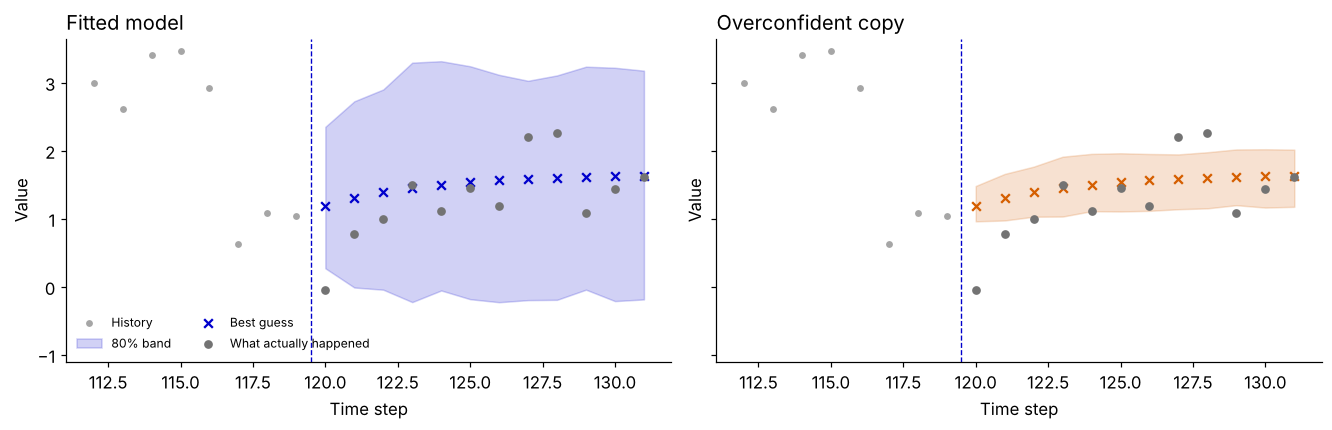

In [4]:
overconfident = mutate_forecast(fitted, "variance_shrink")
forecasts = {"Answer key": answer_key, "Fitted model": fitted, "Overconfident copy": overconfident}


def band_width(forecast):
    return forecast.quantiles[:, :, -1] - forecast.quantiles[:, :, 0]


np.testing.assert_array_equal(overconfident.point, fitted.point)                   # same best guesses
np.testing.assert_allclose(band_width(overconfident), 0.25 * band_width(fitted))  # a quarter of the width

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, layout="constrained")
for ax, name in zip(axes, ["Fitted model", "Overconfident copy"]):
    forecast = forecasts[name]
    ax.scatter(history.index[-8:], history.iloc[-8:], s=12, color="0.65", label="History")
    ax.fill_between(future, forecast.quantiles[:, 0, 0], forecast.quantiles[:, 0, -1],
                    color=COLORS[name], alpha=0.18, label="80% band")
    ax.scatter(future, forecast.point[:, 0], marker="x", s=32, color=COLORS[name], label="Best guess")
    ax.scatter(future, case.observed.iloc[:, 0], s=22, color="0.45", label="What actually happened")
    ax.axvline(future[0] - 0.5, color="#0000CC", linestyle="--", linewidth=0.9)
    ax.set(title=name, xlabel="Time step", ylabel="Value")
axes[0].set_ylim(bottom=-1.1)  # room for the legend
axes[0].legend(fontsize=8, ncol=2, loc="lower left")
plt.show()

The crosses are in exactly the same places. The orange band is a quarter as wide, and 6 of the 12 actual values now fall outside it.

To see the change at a single step, look at step 6 as a distribution: a histogram of the 256 sample values, with the answer key's true curve on top.

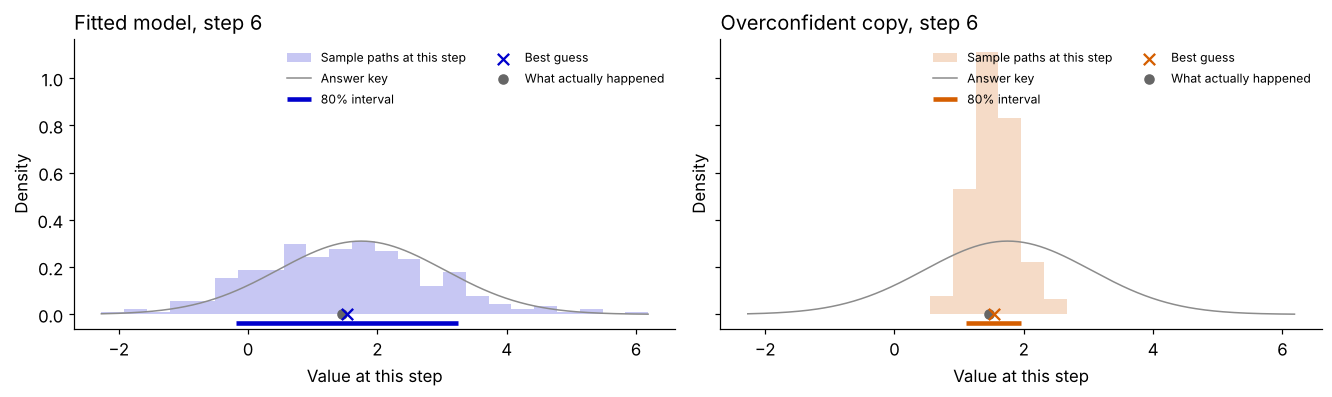

Overconfident 80% interval at step 6: 1.10 to 1.96; what actually happened: 1.45.


In [5]:
step = 5  # the sixth step ahead
names = ["Fitted model", "Overconfident copy"]
values = np.concatenate([forecasts[name].samples[:, step, 0] for name in names]
                        + [case.observed.to_numpy()[step]])
limits = (values.min() - 0.25, values.max() + 0.25)
bins = np.linspace(*limits, 25)
x = np.linspace(*limits, 300)
mu = case.reference.mean[step, 0]
sd = np.sqrt(case.reference.variance[step, 0])
true_density = np.exp(-0.5 * ((x - mu) / sd)**2) / (sd * np.sqrt(2 * np.pi))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True, sharey=True, layout="constrained")
for ax, name in zip(axes, names):
    forecast = forecasts[name]
    ax.hist(forecast.samples[:, step, 0], bins=bins, density=True,
            color=COLORS[name], alpha=0.22, label="Sample paths at this step")
    ax.plot(x, true_density, color="0.55", linewidth=1, label="Answer key")
    interval = forecast.quantiles[step, 0, [0, -1]]
    ax.plot(interval, [-0.035, -0.035], color=COLORS[name], linewidth=3,
            solid_capstyle="butt", label="80% interval")
    ax.scatter(forecast.point[step, 0], 0, marker="x", s=55,
               color=COLORS[name], linewidths=1.5, zorder=5, label="Best guess")
    ax.scatter(case.observed.iloc[step, 0], 0, s=35, color="0.4", zorder=4, label="What actually happened")
    ax.set(title=f"{name}, step {step + 1}", xlabel="Value at this step", ylabel="Density")
    ax.legend(fontsize=8, ncol=2)
axes[0].set_ylim(bottom=-0.06)
plt.show()
print(f"Overconfident 80% interval at step {step + 1}: {overconfident.quantiles[step, 0, 0]:.2f} "
      f"to {overconfident.quantiles[step, 0, -1]:.2f}; what actually happened: "
      f"{case.observed.iloc[step, 0]:.2f}.")

The fitted model's histogram roughly follows the answer key's curve. The overconfident copy piles into a narrow spike. Yet the actual value at this step happens to land inside even that narrow interval.

## On this one series, overconfidence wins

Now score all three forecasts against what actually happened. Every score here is a loss, so lower is better:

- **MAE** and **MSE** (mean absolute and mean squared error) score the best guesses only.
- **Pinball loss** scores the three quantiles.
- **CRPS** (continuous ranked probability score) scores the whole spread of samples at each step. It rewards a forecast for being close to what happened and for being tight about it, and punishes confident misses.

We also count the share of actual values inside the 80% band (**80% coverage**, which should be near 0.8) and the band's average width.

In [6]:
def inside_band(observed, forecast):
    # One yes/no per step: did the actual value land inside the 80% band?
    return ((observed >= forecast.quantiles[:, :, 0]) & (observed <= forecast.quantiles[:, :, -1]))[:, 0]


def scores(observed, forecast):
    return {"MAE": metrics.mae(observed, forecast.point),
            "MSE": metrics.mse(observed, forecast.point),
            "Pinball": metrics.pinball(observed, forecast.quantiles, forecast.levels),
            "CRPS": metrics.crps(observed, forecast.samples),
            "80% coverage": float(np.mean(inside_band(observed, forecast))),
            "Band width": float(np.mean(band_width(forecast)))}


observed = case.observed.to_numpy()
one_series = pd.DataFrame({name: scores(observed, forecast) for name, forecast in forecasts.items()}).T
display(one_series.round(3))

,MAE,MSE,Pinball,CRPS,80% coverage,Band width
Answer key,0.53,0.363,0.20,0.405,0.917,3.130
Fitted model,0.42,0.281,0.19,0.402,0.917,3.167
Overconfident copy,0.42,0.281,0.15,0.328,0.500,0.792


The fitted model and its overconfident copy have the same MAE and MSE, as they must. But the overconfident copy wins on CRPS (0.33 against 0.40) and on pinball loss, even though only half of the actual values fell inside its 80% band. The actual values happened to land unusually close to the best guesses here (an MAE of 0.42, against about 1.0 on a typical series below), and a tight forecast that is close gets rewarded. Luck cuts the other way too: the answer key, which knows the true process, has a worse MAE and MSE than the fitted model on this series.

## What TimeGym says

Before collecting more evidence, ask TimeGym what it makes of the overconfident copy on this series.

In [7]:
verdict = evaluate_forecast(case, overconfident)
for d in verdict.diagnostics:
    print(f"{d.name:<18} {d.status:<13} {d.message}")
status = {d.name: d.status for d in verdict.diagnostics}
assert status["forecast_contract"] == "PASS"          # nothing is broken
assert status["interval_coverage"] == "INCONCLUSIVE"  # scored, but one series can't settle it
coverage_check = next(d for d in verdict.diagnostics if d.name == "interval_coverage")
print(f"\nRecorded: {coverage_check.evidence['observed_coverage']:.0%} of actual values inside a band "
      f"that promised {coverage_check.evidence['nominal_coverage']:.0%}.")

forecast_contract  PASS          Forecast indices, target order, shapes, finiteness, and quantile order satisfy the declared contract.
point_accuracy     INCONCLUSIVE  Point scores are descriptive; no capability acceptance tolerance was declared.
quantile_accuracy  INCONCLUSIVE  Quantile loss is descriptive; no capability acceptance tolerance was declared.
interval_coverage  INCONCLUSIVE  One-path coverage across possibly dependent coordinates does not establish calibration.
sample_scores      INCONCLUSIVE  Empirical marginal and joint scores are descriptive; no capability acceptance tolerance was declared.

Recorded: 50% of actual values inside a band that promised 80%.


The output checks (`forecast_contract`) PASS: right dates, right shape, finite numbers, quantiles in order. Nothing is broken. The four scoring checks are **INCONCLUSIVE**: TimeGym scored them, but no pass mark was set, and TimeGym won't invent one. The coverage check (`interval_coverage`) also says why one series can't settle the question: its 12 steps are linked, because each value carries over most of the one before, so 6 misses out of 12 are not 12 independent pieces of evidence. The scores above showed how one series can mislead. To judge uncertainty we need many independent series.

## Eighty new series

We repeat the experiment on 80 new series from the same process: new history, a freshly fitted model, a new overconfident copy, and new scores for all three forecasts. The series are independent, so at each step we get 80 independent answers to "did the actual value land inside the 80% band?".

In [8]:
N_SERIES = 80
rows, inside = [], {name: [] for name in forecasts}
for seed in range(1000, 1000 + N_SERIES):
    run = scenario.generate(seed=seed)
    fitted_run = (GaussianAR1Forecaster(n_samples=N_SAMPLES, seed=20_000 + seed)
                  .fit(run.task.context).predict(run.task.future_index))
    predictions = {"Answer key": run.reference.forecast(n_samples=N_SAMPLES, seed=10_000 + seed),
                   "Fitted model": fitted_run,
                   "Overconfident copy": mutate_forecast(fitted_run, "variance_shrink")}
    run_observed = run.observed.to_numpy()
    for name, prediction in predictions.items():
        rows.append({"series": seed, "forecast": name, **scores(run_observed, prediction)})
        inside[name].append(inside_band(run_observed, prediction))
per_series = pd.DataFrame(rows)
inside = {name: np.array(hits) for name, hits in inside.items()}  # (series, steps) of yes/no

For each step, the plot shows the share of the 80 series whose actual value fell inside the 80% band. The error bars are 95% intervals for that share (Wilson intervals): how far it could move by chance with only 80 series.

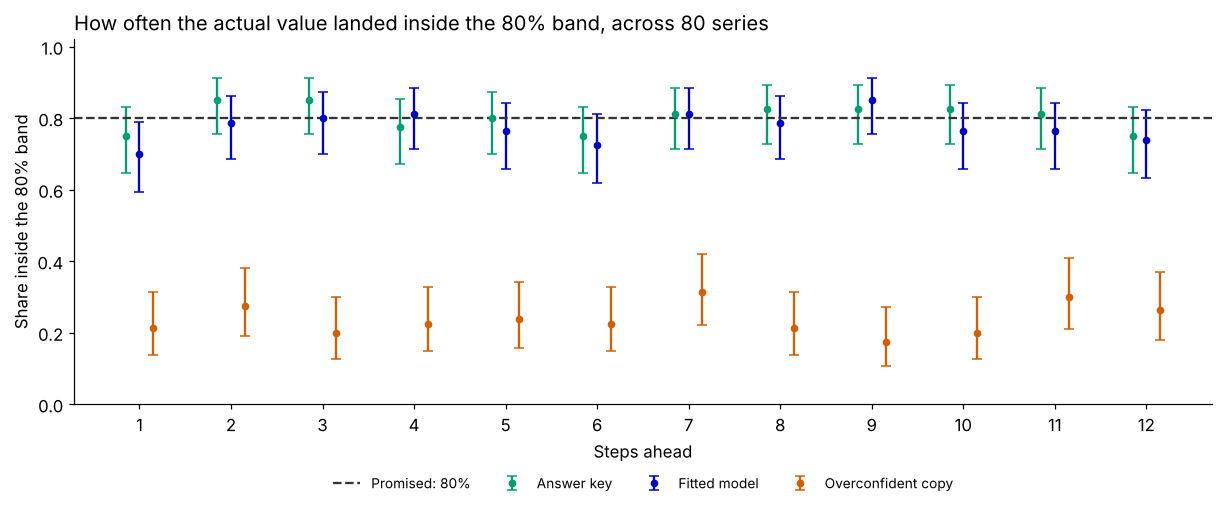

In [9]:
steps = np.arange(1, HORIZON + 1)
fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
for offset, (name, hits) in zip([-0.15, 0, 0.15], inside.items()):
    shares = [wilson_interval(hits[:, h]) for h in range(HORIZON)]
    rate = np.array([share["rate"] for share in shares])
    lower, upper = np.array([share["ci95"] for share in shares]).T
    ax.errorbar(steps + offset, rate, yerr=[rate - lower, upper - rate],
                fmt="o", capsize=3, markersize=4, color=COLORS[name], label=name)
ax.axhline(0.8, color="#333333", linestyle="--", label="Promised: 80%")
ax.set(xlabel="Steps ahead", ylabel="Share inside the 80% band", ylim=(0, 1.02), xticks=steps,
       title="How often the actual value landed inside the 80% band, across 80 series")
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4)
plt.show()

The answer key stays near 80% at every step. So does the fitted model, running a little low at some steps (70% at the first), which fits a model that treats its estimated parameters as exact. The overconfident copy catches only 18% to 31% of the actual values at each step, and its error bars come nowhere near 80%.

## Same series, two forecasts

Each series was forecast both ways, so we can subtract the fitted model's score from the overconfident copy's score within each series. That cancels most of each series' luck (a hard series is hard for both forecasts) and leaves the effect of the shrink. A positive difference means the overconfident copy did worse; the 95% interval says how sure we are of the average difference.

In [10]:
rows, change = [], {}
for score in ["MAE", "MSE", "Pinball", "CRPS", "80% coverage", "Band width"]:
    table = per_series.pivot(index="series", columns="forecast", values=score)
    change[score] = paired_t_interval(table["Overconfident copy"] - table["Fitted model"])
    rows.append({"score": score, **table[list(forecasts)].mean().round(3),
                 "overconfident minus fitted": round(change[score]["mean"], 3),
                 "95% interval": f"{change[score]['ci95'][0]:.3f} to {change[score]['ci95'][1]:.3f}"})
display(pd.DataFrame(rows).set_index("score"))
assert change["MAE"]["mean"] == change["MSE"]["mean"] == 0  # point scores are blind
assert change["CRPS"]["ci95"][0] > 0                       # CRPS sees overconfidence

crps = per_series.pivot(index="series", columns="forecast", values="CRPS")
wins = int((crps["Overconfident copy"] < crps["Fitted model"]).sum())
print(f"The overconfident copy still had the better CRPS on {wins} of the {N_SERIES} series.")

,Answer key,Fitted model,Overconfident copy,overconfident minus fitted,95% interval
score,,,,,
MAE,0.967,1.001,1.001,0.000,0.000 to 0.000
MSE,1.491,1.620,1.620,0.000,0.000 to 0.000
Pinball,0.303,0.319,0.417,0.098,0.081 to 0.114
CRPS,0.693,0.718,0.865,0.147,0.121 to 0.173
80% coverage,0.802,0.775,0.236,-0.539,-0.575 to -0.502
Band width,3.130,2.997,0.749,-2.248,-2.307 to -2.188


The overconfident copy still had the better CRPS on 6 of the 80 series.


Averaged over 80 series, the overconfident copy loses on every score that looks at uncertainty. CRPS is worse by 0.15 (95% interval 0.12 to 0.17), pinball loss by 0.10, and its bands, 2.2 units narrower, catch 54 percentage points fewer of the actual values. MAE and MSE differ by exactly zero. Yet on 6 of the 80 series, as on the first one, the overconfident copy still had the better CRPS.

## What you learned

- Point scores can't see uncertainty: shrink the spread and MAE and MSE don't move.
- On one series an overconfident forecast can beat an honest one. Judge uncertainty across many independent series, comparing the same series forecast both ways.
- TimeGym separates broken from weak: the overconfident forecast passes the output checks, and its scores are recorded for you to judge.

## Change one thing

- Shorten the history to 20 values, then lengthen it to 500 (`context_length`), and watch how far the fitted model's coverage drifts from the answer key's.
- Raise `N_SAMPLES` to see how much of the wobble in the bands comes from having only 256 sample paths.
- Change `phi` or `sigma`, and keep counting whole series, not steps, as your evidence.
- Swap in your own model: anything with `fit(history)` and `predict(dates)` that returns sample paths shaped (paths, steps, targets).

**What this doesn't show.** The bands are 80% bands for each step on its own; a whole 12-step path stays inside all twelve of them far less often than 80% of the time. TimeGym's CRPS is the plain sample version, not the "fair" ensemble version, so its values differ slightly from tools that use the latter. Each interval here is read on its own, with no correction for looking at many at once.

Reading: [Gneiting and Raftery (2007)](https://doi.org/10.1198/016214506000001437).

**Next:** [Multivariate uncertainty](09_multivariate_uncertainty.ipynb).